In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('titanic_toy.csv')

In [4]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [5]:
df.isnull().sum()

Age         177
Fare         45
Family        0
Survived      0
dtype: int64

In [6]:
df.isnull().mean()

Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64

In [7]:
x = df.drop('Survived', axis=1)
y = df['Survived']

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

In [9]:
x_train.shape, x_test.shape


((712, 3), (179, 3))

In [10]:
x_train.isnull().mean()

Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64

In [11]:
mean_age = x_train['Age'].mean()
median_age = x_train['Age'].median()

mean_fare = x_train['Fare'].mean()
median_fare = x_train['Fare'].median()


In [12]:
x_train['Median_age'] = x_train['Age'].fillna(median_age)
x_train['Mean_age'] = x_train['Age'].fillna(mean_age)

x_train['Median_Fare'] = x_train['Fare'].fillna(median_fare)
x_train['Mean_Fare'] = x_train['Fare'].fillna(mean_fare)



In [13]:
x_train.sample(5)

,Age,Fare,Family,Median_age,Mean_age,Median_Fare,Mean_Fare
326,61.0,6.2375,0,61.0,61.0,6.2375,6.2375
658,23.0,13.0000,0,23.0,23.0,13.0000,13.0000
733,23.0,13.0000,0,23.0,23.0,13.0000,13.0000
770,24.0,9.5000,0,24.0,24.0,9.5000,9.5000
603,44.0,8.0500,0,44.0,44.0,8.0500,8.0500


In [14]:
print("original Age variable variance : ", x_train['Age'].var())
print("Age variance after median imputation : ", x_train['Median_age'].var())
print("Age variance after mean imputation : ", x_train['Mean_age'].var())

print("original Fare variable variance : ", x_train['Fare'].var())
print("Fare variance after median variance : ",x_train['Median_Fare'].var())
print("Fare variance after mean variance : ",x_train['Mean_Fare'].var())



original Age variable variance :  204.34951339046142
Age variance after median imputation :  161.98956633460548
Age variance after mean imputation :  161.81262452718676
original Fare variable variance :  2448.1979137063163
Fare variance after median variance :  2340.09102197536
Fare variance after mean variance :  2324.2385256705534


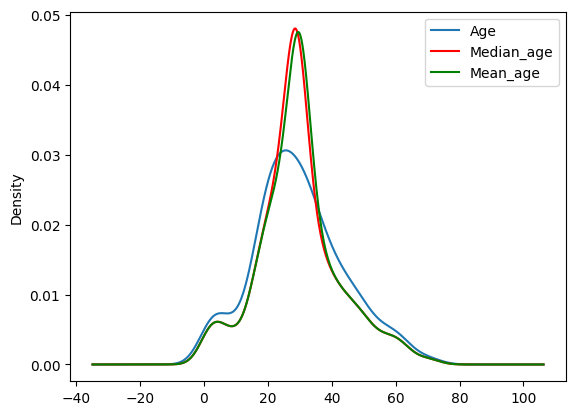

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
x_train['Age'].plot(kind='kde', ax=ax)

# variable imputed with the median
x_train['Median_age'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
x_train['Mean_age'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

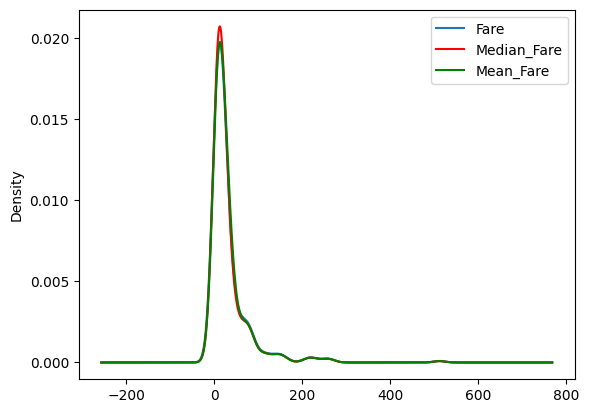

In [16]:
fig = plt.figure()
ax = fig.add_subplot(111)

# original variable distribution
x_train['Fare'].plot(kind='kde', ax=ax)

# variable imputed with the median
x_train['Median_Fare'].plot(kind='kde', ax=ax, color='red')

# variable imputed with the mean
x_train['Mean_Fare'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

# Almost overlap this graph is fine 